In [3]:
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.2.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd

# Load the downloaded CSV file into a Pandas DataFrame
df = pd.read_csv('I1.csv')

# Look at the first 5 rows of our data
df.head()

,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,...,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA,BFECAHH,BFECAHA
0,I1,23/08/2025,17:30,Genoa,Lecce,0,0,D,0,0,...,2.03,1.83,2.00,1.93,2.03,1.88,1.94,1.80,2.11,1.88
1,I1,23/08/2025,17:30,Sassuolo,Napoli,0,2,A,0,1,...,2.03,1.83,2.08,1.85,2.06,1.83,1.97,1.78,2.07,1.91
2,I1,23/08/2025,19:45,Milan,Cremonese,1,2,A,1,1,...,1.93,1.93,2.22,1.72,2.10,1.93,1.98,1.79,2.02,1.94
3,I1,23/08/2025,19:45,Roma,Bologna,1,0,H,0,0,...,1.88,1.98,1.85,2.09,1.88,2.05,1.76,1.99,1.92,2.07
4,I1,24/08/2025,17:30,Cagliari,Fiorentina,1,1,D,0,0,...,1.70,2.10,1.98,1.94,1.83,2.10,1.77,1.93,1.83,2.17


In [5]:
# 1. See how many rows (matches) and columns (stats) we have
print("Dataset Shape (Rows, Columns):", df.shape)

# 2. Print all column names so we know what's in here
print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape (Rows, Columns): (380, 131)

Column Names:
['Div', 'Date', 'Time', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'HTHG', 'HTAG', 'HTR', 'HS', 'AS', 'HST', 'AST', 'HF', 'AF', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR', 'B365H', 'B365D', 'B365A', 'BFDH', 'BFDD', 'BFDA', 'BMGMH', 'BMGMD', 'BMGMA', 'BVH', 'BVD', 'BVA', 'BWH', 'BWD', 'BWA', 'CLH', 'CLD', 'CLA', 'LBH', 'LBD', 'LBA', 'PSH', 'PSD', 'PSA', 'MaxH', 'MaxD', 'MaxA', 'AvgH', 'AvgD', 'AvgA', 'BFEH', 'BFED', 'BFEA', 'B365>2.5', 'B365<2.5', 'P>2.5', 'P<2.5', 'Max>2.5', 'Max<2.5', 'Avg>2.5', 'Avg<2.5', 'BFE>2.5', 'BFE<2.5', 'AHh', 'B365AHH', 'B365AHA', 'PAHH', 'PAHA', 'MaxAHH', 'MaxAHA', 'AvgAHH', 'AvgAHA', 'BFEAHH', 'BFEAHA', 'B365CH', 'B365CD', 'B365CA', 'BFDCH', 'BFDCD', 'BFDCA', 'BMGMCH', 'BMGMCD', 'BMGMCA', 'BVCH', 'BVCD', 'BVCA', 'BWCH', 'BWCD', 'BWCA', 'CLCH', 'CLCD', 'CLCA', 'LBCH', 'LBCD', 'LBCA', 'PSCH', 'PSCD', 'PSCA', 'MaxCH', 'MaxCD', 'MaxCA', 'AvgCH', 'AvgCD', 'AvgCA', 'BFECH', 'BFECD', 'BFECA', 'B365C>2.5', 'B365C

In [6]:
# Calculate home goals scored by each team
home_goals = df.groupby('HomeTeam')['FTHG'].sum()

# Calculate away goals scored by each team
away_goals = df.groupby('AwayTeam')['FTAG'].sum()

# Combine home and away goals into one total
total_goals = (home_goals + away_goals).sort_values(ascending=False)

# Display the top scoring teams
print("Top Scoring Teams in Serie A:")
print(total_goals)

Top Scoring Teams in Serie A:
HomeTeam
Inter         89
Como          65
Juventus      61
Roma          59
Napoli        58
Milan         53
Atalanta      51
Bologna       49
Sassuolo      46
Udinese       45
Torino        44
Fiorentina    41
Genoa         41
Lazio         41
Cagliari      40
Cremonese     32
Lecce         28
Parma         28
Pisa          26
Verona        25
dtype: int64


In [8]:
# Goals conceded at home = FTAG (away team goals scored against them)
home_conceded = df.groupby('HomeTeam')['FTAG'].sum()

# Goals conceded away = FTHG (home team goals scored against them)
away_conceded = df.groupby('AwayTeam')['FTHG'].sum()

# Total goals conceded sorted from highest (leakiest) to lowest
total_conceded = (home_conceded + away_conceded).sort_values(ascending=False)

print("Teams with Most Goals Conceded in Serie A:")
print(total_conceded)

Teams with Most Goals Conceded in Serie A:
HomeTeam
Pisa          71
Torino        63
Verona        61
Cremonese     57
Cagliari      53
Genoa         51
Fiorentina    50
Sassuolo      50
Lecce         50
Udinese       48
Bologna       46
Parma         46
Lazio         40
Atalanta      36
Napoli        36
Inter         35
Milan         35
Juventus      34
Roma          31
Como          29
dtype: int64


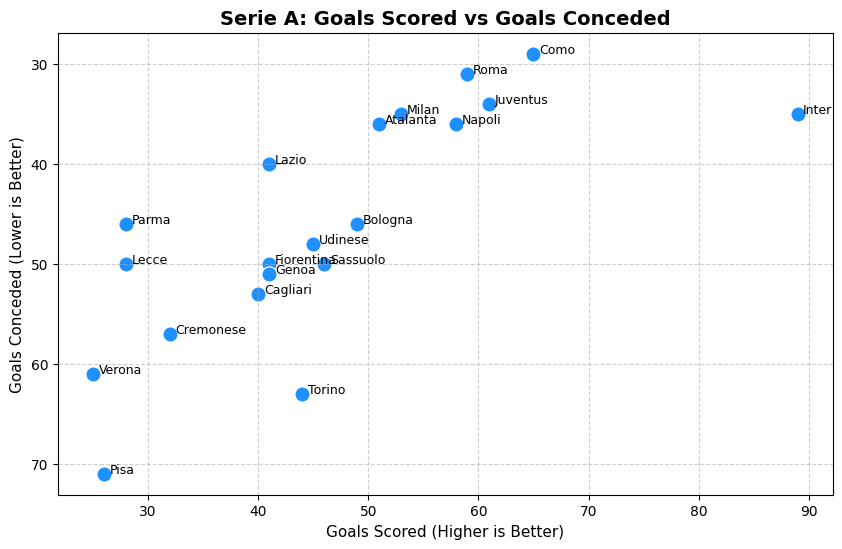

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Put our calculated stats into a clean DataFrame
team_stats = pd.DataFrame(
    {'Goals_Scored': total_goals, 'Goals_Conceded': total_conceded}
)

# Set up the plot window
plt.figure(figsize=(10, 6))

# Draw the scatter plot
sns.scatterplot(
    data=team_stats,
    x='Goals_Scored',
    y='Goals_Conceded',
    s=120,
    color='dodgerblue',
)

# Add team labels next to each point on the graph
for team in team_stats.index:
    plt.text(
        team_stats.loc[team, 'Goals_Scored'] + 0.5,
        team_stats.loc[team, 'Goals_Conceded'],
        team,
        fontsize=9,
    )

# Customize title and labels
plt.title('Serie A: Goals Scored vs Goals Conceded', fontsize=14, fontweight='bold')
plt.xlabel('Goals Scored (Higher is Better)', fontsize=11)
plt.ylabel('Goals Conceded (Lower is Better)', fontsize=11)

# Invert Y axis so top means fewer goals conceded (better defence!)
plt.gca().invert_yaxis()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

In [10]:
# Function to calculate points for each match
def get_home_points(row):
    if row['FTHG'] > row['FTAG']:
        return 3  # Home Win
    elif row['FTHG'] == row['FTAG']:
        return 1  # Draw
    else:
        return 0  # Away Win


def get_away_points(row):
    if row['FTAG'] > row['FTHG']:
        return 3  # Away Win
    elif row['FTHG'] == row['FTAG']:
        return 1  # Draw
    else:
        return 0  # Home Win


# Calculate points per match
df['HomePoints'] = df.apply(get_home_points, axis=1)
df['AwayPoints'] = df.apply(get_away_points, axis=1)

# Sum total home points and away points per team
home_pts = df.groupby('HomeTeam')['HomePoints'].sum()
away_pts = df.groupby('AwayTeam')['AwayPoints'].sum()

# Combine into a single comparison DataFrame
home_away_df = (
    pd.DataFrame({'Home Points': home_pts, 'Away Points': away_pts})
    .fillna(0)
    .astype(int)
)

# Calculate difference (Home Points - Away Points)
home_away_df['Home Advantage Diff'] = (
    home_away_df['Home Points'] - home_away_df['Away Points']
)

print(home_away_df.sort_values(by='Home Points', ascending=False))

            Home Points  Away Points  Home Advantage Diff
Inter                45           42                    3
Napoli               43           33                   10
Roma                 42           31                   11
Juventus             37           32                    5
Como                 36           35                    1
Atalanta             33           26                    7
Milan                32           38                   -6
Lazio                30           24                    6
Sassuolo             29           20                    9
Torino               28           17                   11
Cagliari             25           18                    7
Udinese              23           27                   -4
Bologna              22           34                  -12
Genoa                22           19                    3
Fiorentina           21           21                    0
Parma                21           24                   -3
Lecce         

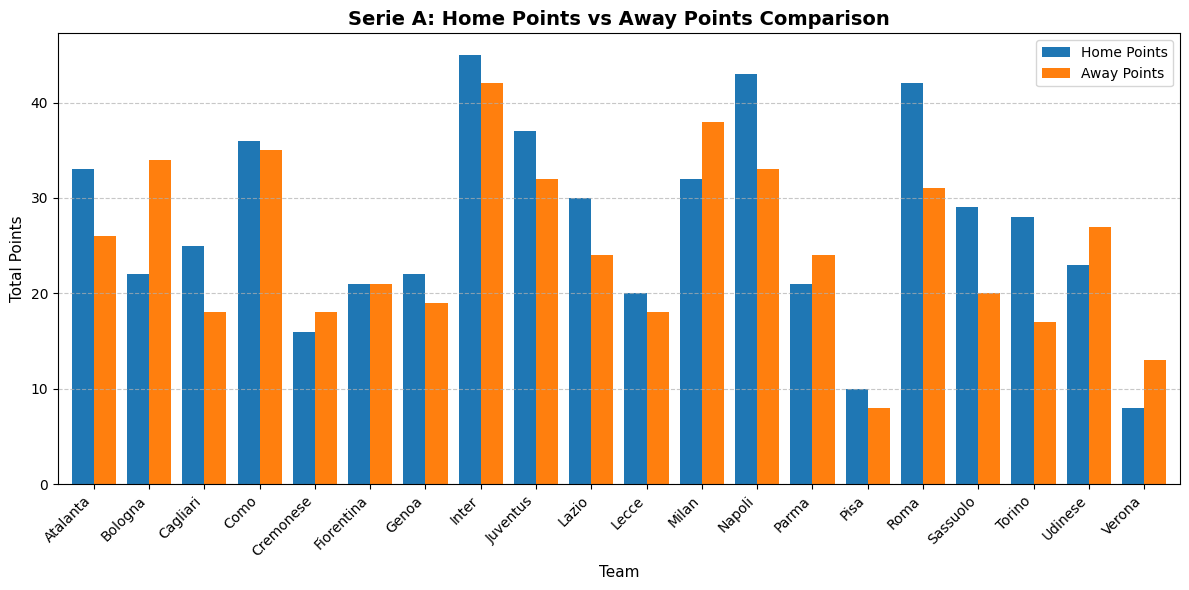

In [11]:
# Plot side-by-side bar chart
home_away_df[['Home Points', 'Away Points']].plot(
    kind='bar', figsize=(12, 6), color=['#1f77b4', '#ff7f0e'], width=0.8
)

plt.title('Serie A: Home Points vs Away Points Comparison', fontsize=14, fontweight='bold')
plt.xlabel('Team', fontsize=11)
plt.ylabel('Total Points', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(['Home Points', 'Away Points'])
plt.tight_layout()

plt.show()

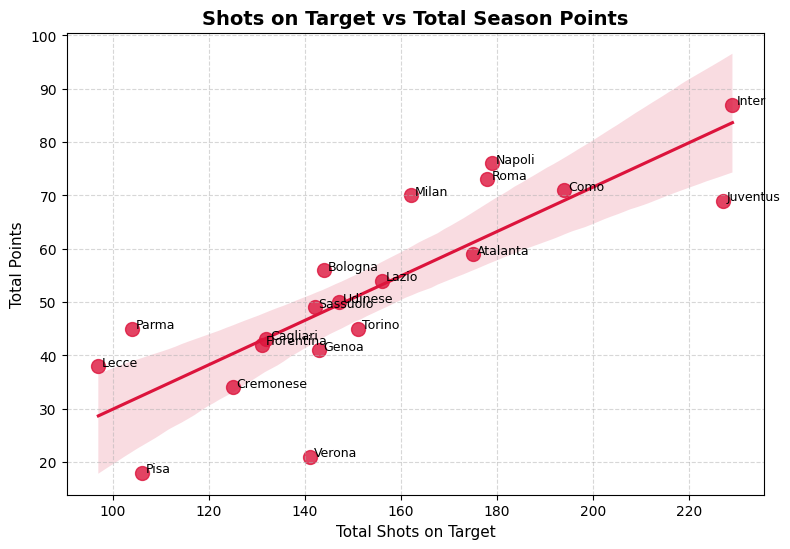

In [12]:
# Calculate Total Shots and Total Points for each team
home_shots = df.groupby('HomeTeam')['HS'].sum()
away_shots = df.groupby('AwayTeam')['AS'].sum()
total_shots = home_shots + away_shots

home_shots_target = df.groupby('HomeTeam')['HST'].sum()
away_shots_target = df.groupby('AwayTeam')['AST'].sum()
total_shots_target = home_shots_target + away_shots_target

total_points = home_pts + away_pts

# Combine into a summary DataFrame
stats_summary = pd.DataFrame(
    {
        'Total Points': total_points,
        'Total Shots': total_shots,
        'Shots on Target': total_shots_target,
    }
)

# Plot correlation scatter plot
plt.figure(figsize=(9, 6))
sns.regplot(
    data=stats_summary,
    x='Shots on Target',
    y='Total Points',
    color='crimson',
    marker='o',
    scatter_kws={'s': 100},
)

# Add team labels
for team in stats_summary.index:
    plt.text(
        stats_summary.loc[team, 'Shots on Target'] + 0.8,
        stats_summary.loc[team, 'Total Points'],
        team,
        fontsize=9,
    )

plt.title('Shots on Target vs Total Season Points', fontsize=14, fontweight='bold')
plt.xlabel('Total Shots on Target', fontsize=11)
plt.ylabel('Total Points', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

In [13]:
# Filter matches where at least one team scored in the first half
first_half_goals = df[(df['HTHG'] > 0) | (df['HTAG'] > 0)].copy()


# Determine match outcome for the team that scored first in the 1st half
def analyze_first_scorer_outcome(row):
    # Home team scored first
    if row['HTHG'] > row['HTAG']:
        if row['FTHG'] > row['FTAG']:
            return 'Win'
        elif row['FTHG'] == row['FTAG']:
            return 'Draw'
        else:
            return 'Loss (Conceded Comeback)'
    # Away team scored first
    elif row['HTAG'] > row['HTHG']:
        if row['FTAG'] > row['FTHG']:
            return 'Win'
        elif row['FTAG'] == row['FTHG']:
            return 'Draw'
        else:
            return 'Loss (Conceded Comeback)'
    return 'Both Scored equal in 1st Half'


first_half_goals['First_Scorer_Outcome'] = first_half_goals.apply(
    analyze_first_scorer_outcome, axis=1
)

# Filter out equal first half goals (e.g. 1-1 at half time)
outcomes = first_half_goals[
    first_half_goals['First_Scorer_Outcome'] != 'Both Scored equal in 1st Half'
]['First_Scorer_Outcome'].value_counts(normalize=True) * 100

print("Outcome for Teams That Score First (%):")
print(outcomes.round(1))

Outcome for Teams That Score First (%):
First_Scorer_Outcome
Win                         77.5
Draw                        16.4
Loss (Conceded Comeback)     6.1
Name: proportion, dtype: float64


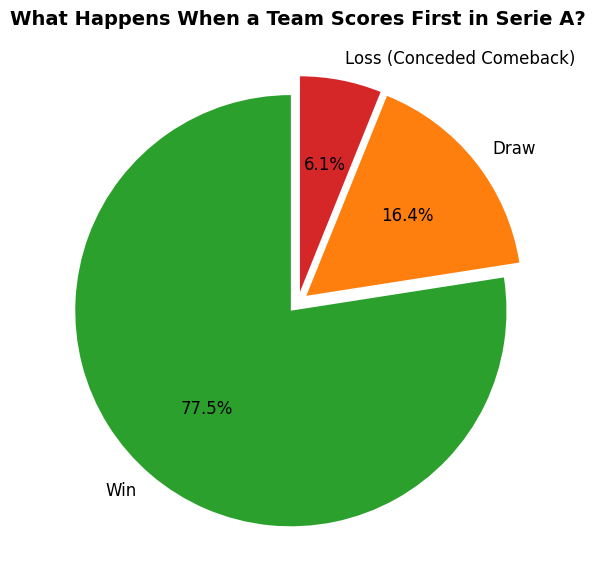

In [14]:
plt.figure(figsize=(7, 7))
colors = ['#2ca02c', '#ff7f0e', '#d62728']

outcomes.plot(
    kind='pie',
    autopct='%1.1f%%',
    colors=colors,
    startangle=90,
    explode=(0.05, 0.05, 0.05),
    textprops={'fontsize': 12},
)

plt.title(
    'What Happens When a Team Scores First in Serie A?',
    fontsize=14,
    fontweight='bold',
)
plt.ylabel('')  # Hide y-label for clean look
plt.show()